# Quickstart: load the data and reproduce two results

This notebook loads the processed datasets in `data/processed/` and reproduces two findings from the README in a few lines of pandas:

1. **Umpires called fewer strikes outside the zone in 2026**, and more balls inside it.
2. **Catchers read the zone more sharply than batters** when deciding whether to challenge.

The full models (called-zone surfaces, win probability, the perception model, the season simulation) live in `src/`. Column definitions are in [`data/README.md`](../data/README.md).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

called = pd.read_csv("../data/processed/called_pitches_2025_2026.csv.gz")
opps = pd.read_csv("../data/processed/challenge_opportunities_2026.csv.gz")
print(f"called pitches: {len(called):,}   challenge opportunities: {len(opps):,}")
called[["game_year", "plate_x_mid_ft", "plate_z_mid_ft", "edge_distance_in", "abs_strike", "ump_strike"]].head()

called pitches: 740,228   challenge opportunities: 341,624


,game_year,plate_x_mid_ft,plate_z_mid_ft,edge_distance_in,abs_strike,ump_strike
0,2025,-0.8434,1.1794,4.273,0,0
1,2025,-0.3233,1.7318,-2.359,1,1
2,2025,-0.0786,3.7222,3.839,0,0
3,2025,-0.7398,3.5194,1.406,0,0
4,2025,-0.5975,2.9547,-2.780,1,1


## 1. How the umpires' calls changed

`abs_strike` is the ruling under the ABS zone. `ump_strike` is the umpire's original call (2026 overturns are flipped back). Both seasons use the same zone and the same mid-plate location, so the comparison is like-for-like.

In [2]:
zone = called.dropna(subset=["abs_zone_top_ft"])
summary = zone.groupby("game_year").apply(lambda d: pd.Series({
    "called pitches": len(d),
    "strikes called outside ABS zone": d.loc[d.abs_strike == 0, "ump_strike"].mean(),
    "balls called inside ABS zone": 1 - d.loc[d.abs_strike == 1, "ump_strike"].mean(),
    "agreement with ABS": (d.ump_strike == d.abs_strike).mean(),
}), include_groups=False)
summary.style.format({"called pitches": "{:,.0f}", "strikes called outside ABS zone": "{:.1%}",
                      "balls called inside ABS zone": "{:.1%}", "agreement with ABS": "{:.1%}"})

,called pitches,strikes called outside ABS zone,balls called inside ABS zone,agreement with ABS
game_year,,,,
2025,"341,154",6.9%,8.1%,92.8%
2026,"371,385",5.0%,10.1%,93.4%


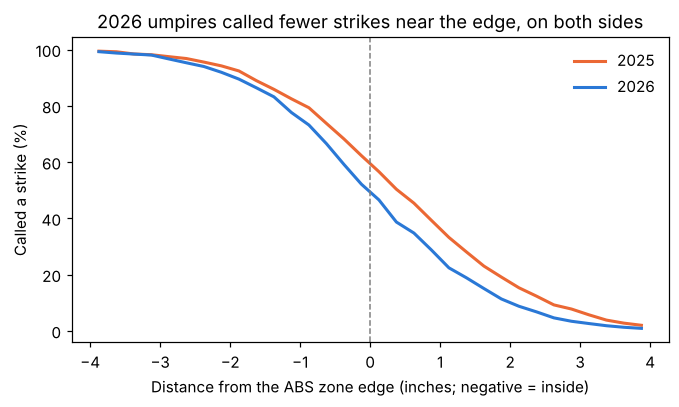

In [3]:
bins = np.arange(-4, 4.25, 0.25)
zone["dist_bin"] = pd.cut(zone.edge_distance_in, bins)
curve = zone.groupby(["game_year", "dist_bin"], observed=True)["ump_strike"].mean().unstack(0)
mid = [b.mid for b in curve.index]

fig, ax = plt.subplots(figsize=(7, 3.6))
for yr, col in [(2025, "#eb6834"), (2026, "#2a78d6")]:
    ax.plot(mid, 100 * curve[yr], color=col, lw=2, label=str(yr))
ax.axvline(0, color="gray", ls="--", lw=1)
ax.set_xlabel("Distance from the ABS zone edge (inches; negative = inside)")
ax.set_ylabel("Called a strike (%)")
ax.set_title("2026 umpires called fewer strikes near the edge, on both sides")
ax.legend(frameon=False)
plt.show()

The 2026 curve sits lower near the edge on both sides. It crosses 50% almost exactly at the zone edge, while 2025 crossed about a third of an inch outside it. So pitches just outside lost strikes, and pitches just inside lost some too. The README's zone-area estimate (471 → 436 sq in, 95% CI on the change: −40 to −29) comes from the 2-D model in `src/analysis.py`.

## 2. Who challenges well

Each row of `opps` is a call that went against a side still holding a challenge. `distance_in_challengers_favor_in > 0` means the call was wrong.

In [4]:
opps["call_wrong"] = opps.distance_in_challengers_favor_in > 0
by_role = opps.groupby("role").apply(lambda d: pd.Series({
    "opportunities": len(d),
    "challenged when call was wrong": d.loc[d.call_wrong, "challenged"].mean(),
    "challenged when call was right": d.loc[~d.call_wrong, "challenged"].mean(),
    "challenges overturned": d.loc[d.challenged == 1, "overturned"].mean(),
}), include_groups=False)
by_role.style.format({"opportunities": "{:,.0f}", "challenged when call was wrong": "{:.1%}",
                      "challenged when call was right": "{:.1%}", "challenges overturned": "{:.1%}"})

,opportunities,challenged when call was wrong,challenged when call was right,challenges overturned
role,,,,
batter,"105,699",19.3%,2.5%,49.0%
catcher,"235,925",31.4%,1.0%,58.2%


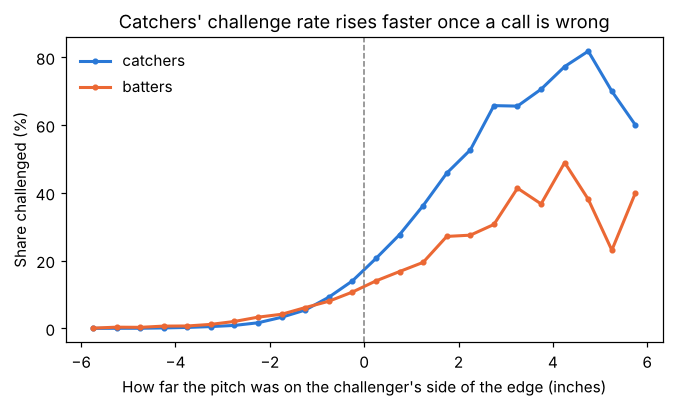

In [5]:
bins = np.arange(-6, 6.5, 0.5)
opps["dist_bin"] = pd.cut(opps.distance_in_challengers_favor_in, bins)
rate = opps.groupby(["role", "dist_bin"], observed=True)["challenged"].mean().unstack(0)
mid = [b.mid for b in rate.index]

fig, ax = plt.subplots(figsize=(7, 3.6))
for role, col in [("catcher", "#2a78d6"), ("batter", "#eb6834")]:
    ax.plot(mid, 100 * rate[role], color=col, lw=2, marker="o", ms=3, label=role + "s")
ax.axvline(0, color="gray", ls="--", lw=1)
ax.set_xlabel("How far the pitch was on the challenger's side of the edge (inches)")
ax.set_ylabel("Share challenged (%)")
ax.set_title("Catchers' challenge rate rises faster once a call is wrong")
ax.legend(frameon=False)
plt.show()

`src/part2_extended.py` fits these curves with a psychometric model that has a lapse rate. That gives an effective judgment error of about 1.5 inches for catchers and 2.4 for batters, and it shows players act on what they see only 70% and 53% of the time. A season-long simulation then turns that into the ~1.5 wins per team left on the table.

## Next steps
- `run_all.sh` rebuilds everything from Baseball Savant.
- `METHODS.md` explains each modeling decision and its alternatives.